# Modelo de dígitos

## Carga de datos MNIST

Cargamos la base de datos de MNIST utilizando tensorflow

In [2]:
import numpy as np
from sklearn import svm, metrics
from sklearn.model_selection import train_test_split
import tensorflow as tf
import matplotlib.pyplot as plt

# Cargar el dataset MNIST con TensorFlow
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Combinar entrenamiento y prueba para usar todo el dataset
X = np.concatenate((x_train, x_test), axis=0)
y = np.concatenate((y_train, y_test), axis=0)

# Aplanar las imágenes (28x28 a vector de 784)
X = X.reshape((X.shape[0], -1))

# Normalizar los valores de los píxeles a rango [0, 1]
X = X.astype('float32') / 255.0

#reducir tamaño para acelerar entrenamiento (ejemplo con 10000 muestras)
indices = np.random.choice(X.shape[0], 10000, replace=False)
X = X[indices]
y = y[indices]

# Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=True, random_state=42)







11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


##SVM

Aplicamos gridsearch en busca de los mejores hiperparámetros

In [3]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# Iniciar SVM
svm = SVC(probability=True, random_state=42)

# Definición de parámetros grid para GridSearchCV
param_grid = [
    {'kernel': ['rbf'], 'C': [0.1, 1, 10], 'gamma': ['scale', 'auto']},
]

print("Modelo SVC y parámetros GridSearchCV definidos")

Modelo SVC y parámetros GridSearchCV definidos


In [4]:
print("\nGridSearchCV para encontrar los mejores hiperparámetros SVM...")
grid_search = GridSearchCV(svm, param_grid, cv=3, scoring='accuracy', n_jobs=-1, verbose=2)
grid_search.fit(X_train, y_train)

print("GridSearchCV se completó")


GridSearchCV para encontrar los mejores hiperparámetros SVM...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
GridSearchCV se completó


In [5]:
best_svm = grid_search.best_estimator_
print(f"\nMejores parámetros encontrados por GridSearchCV: {grid_search.best_params_}")
print(f"Mejor cross-validation accuracy: {grid_search.best_score_:.4f}")

print("Mejores detalles del modelo SVM extraídos.")


Mejores parámetros encontrados por GridSearchCV: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Mejor cross-validation accuracy: 0.9589
Mejores detalles del modelo SVM extraídos.


### Métricas

In [8]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("\nEvaluación del mejor modelo SVM en el conjunto de pruebas...")
y_pred = best_svm.predict(X_test)

# Calcular accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy:.4f}")

# classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))




Evaluación del mejor modelo SVM en el conjunto de pruebas...
Test Accuracy: 0.9630

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       200
           1       0.98      0.99      0.98       222
           2       0.97      0.96      0.97       210
           3       0.94      0.94      0.94       196
           4       0.97      0.97      0.97       197
           5       0.94      0.94      0.94       188
           6       0.97      0.95      0.96       197
           7       0.97      0.97      0.97       206
           8       0.94      0.94      0.94       180
           9       0.97      0.95      0.96       204

    accuracy                           0.96      2000
   macro avg       0.96      0.96      0.96      2000
weighted avg       0.96      0.96      0.96      2000



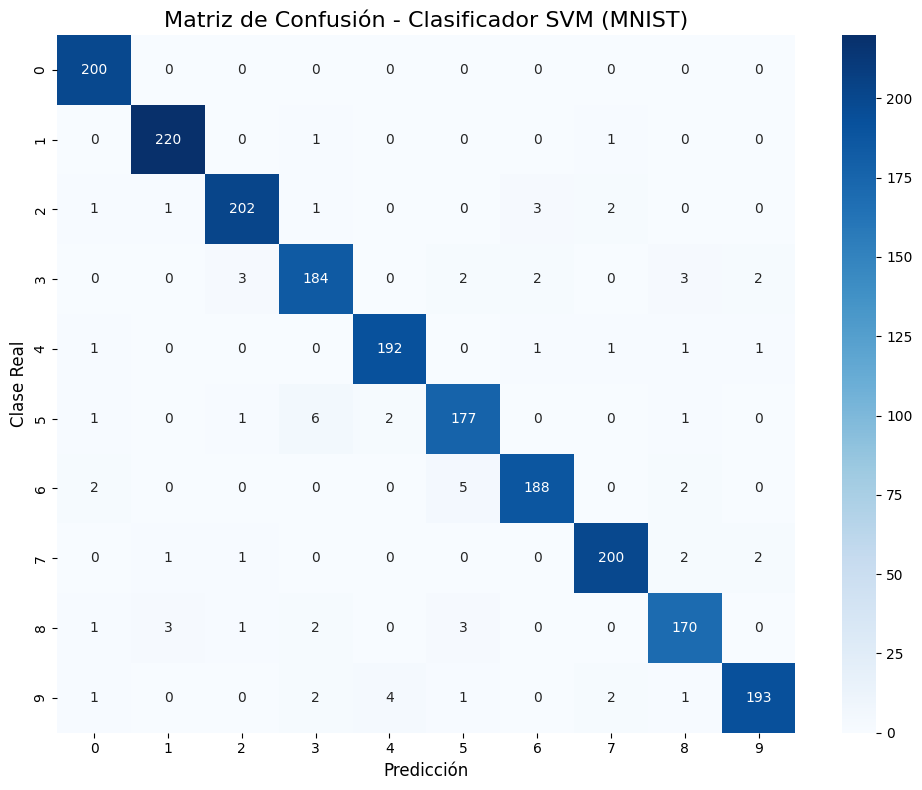

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Calcular explícitamente la matriz de confusión del clasificador SVM
y_pred_svm = best_svm.predict(X_test)
conf_matrix_svm = confusion_matrix(y_test, y_pred_svm)

# Configurar el tamaño de la figura
plt.figure(figsize=(10, 8))

# Crear el mapa de calor usando Seaborn
sns.heatmap(conf_matrix_svm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))

# Añadir etiquetas y título
plt.title('Matriz de Confusión - Clasificador SVM (MNIST)', fontsize=16)
plt.xlabel('Predicción', fontsize=12)
plt.ylabel('Clase Real', fontsize=12)

# Mostrar el gráfico
plt.tight_layout()
plt.show()

Guardar modelo

In [ ]:
import joblib

model_filename = 'digit_model.pkl'
joblib.dump(best_svm, model_filename)
print(f"\nBest SVM model saved to '{model_filename}'")


Best SVM model saved to 'digit_model.pkl'


## Random forest

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Define el modelo base
rf = RandomForestClassifier(random_state=42)

# Define la rejilla de hiperparámetros a probar
param_grid = {
    'n_estimators': [50, 100],        # número de árboles
    'max_depth': [50, 100],            # profundidad máxima de los árboles
    'min_samples_split': [5, 10],     # mínimo de muestras para dividir un nodo
    'min_samples_leaf': [2, 4],         # mínimo de muestras en una hoja
    'bootstrap': [False]               # usar bootstrap o no (simplificado a True)
}

# Configura GridSearchCV
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, scoring='accuracy', cv=3, n_jobs=-1, verbose=2)

# Entrena con tus datos
grid_search.fit(X_train, y_train)

# Mejor modelo
best_rf = grid_search.best_estimator_

# Mejores hiperparámetros
print("Mejores hiperparámetros:", grid_search.best_params_)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Mejores hiperparámetros: {'bootstrap': False, 'max_depth': 50, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}


### Métricas

In [17]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("\nEvaluating the best rf model on the test set...")
y_pred = best_rf.predict(X_test)

# Calcular accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy:.4f}")

# classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))



Evaluating the best rf model on the test set...
Test Accuracy: 0.9420

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       200
           1       0.97      0.98      0.98       222
           2       0.91      0.95      0.93       210
           3       0.89      0.91      0.90       196
           4       0.95      0.96      0.95       197
           5       0.93      0.89      0.91       188
           6       0.98      0.96      0.97       197
           7       0.95      0.95      0.95       206
           8       0.91      0.91      0.91       180
           9       0.95      0.91      0.93       204

    accuracy                           0.94      2000
   macro avg       0.94      0.94      0.94      2000
weighted avg       0.94      0.94      0.94      2000



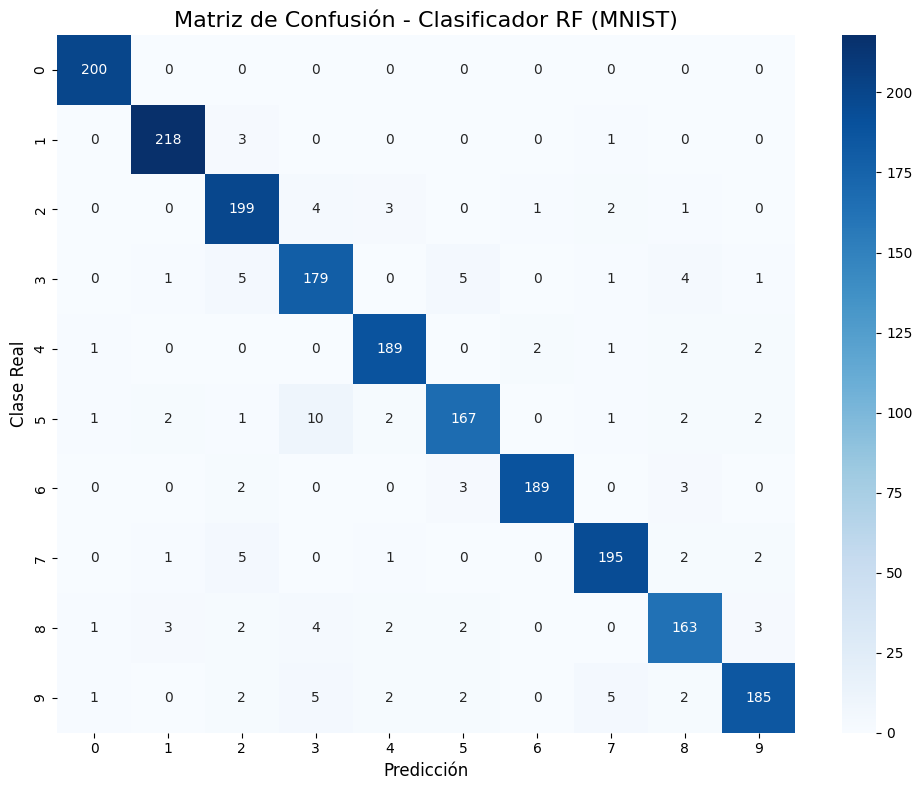

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Calcular explícitamente la matriz de confusión del clasificador SVM
y_pred = best_rf.predict(X_test)
conf_matrix_rf = confusion_matrix(y_test, y_pred)

# Configurar el tamaño de la figura
plt.figure(figsize=(10, 8))

# Crear el mapa de calor usando Seaborn
sns.heatmap(conf_matrix_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))

# Añadir etiquetas y título
plt.title('Matriz de Confusión - Clasificador RF (MNIST)', fontsize=16)
plt.xlabel('Predicción', fontsize=12)
plt.ylabel('Clase Real', fontsize=12)

# Mostrar el gráfico
plt.tight_layout()
plt.show()

Guardar modelo rf

In [ ]:
import joblib

model_filename = 'digit_model_rf.pkl'
joblib.dump(best_rf, model_filename)
print(f"\nBest SVM model saved to '{model_filename}'")


Best SVM model saved to 'digit_model_rl.pkl'


## Red Neuronal Convolucional (CNN)

Las CNNs son ideales para datos espaciales como imágenes. En esta sección redimensionaremos nuestros datos a 2D (28x28x1) y entrenaremos un modelo convolucional usando Keras.

In [20]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Redimensionar los datos a formato de imagen 2D (28x28x1) para la CNN
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

print(f"Forma de entrenamiento para CNN: {X_train_cnn.shape}")
print(f"Forma de prueba para CNN: {X_test_cnn.shape}")

Forma de entrenamiento para CNN: (8000, 28, 28, 1)
Forma de prueba para CNN: (2000, 28, 28, 1)


In [21]:
# 2. Definir la arquitectura de la CNN usando Input para evitar advertencias
model_cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    # Primera capa convolucional
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Segunda capa convolucional
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Aplanar las características para la capa densa
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),  # Regularización
    layers.Dense(10, activation='softmax')  # Capa de salida para 10 clases
])

# 3. Compilar el modelo
model_cnn.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

model_cnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# 4. Entrenar la CNN
history = model_cnn.fit(X_train_cnn, y_train, epochs=10, batch_size=64, validation_split=0.1)

Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.7296 - loss: 0.8621 - val_accuracy: 0.9200 - val_loss: 0.2777
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 10s 51ms/step - accuracy: 0.9185 - loss: 0.2725 - val_accuracy: 0.9488 - val_loss: 0.1884
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.9510 - loss: 0.1751 - val_accuracy: 0.9575 - val_loss: 0.1489
Epoch 4/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - accuracy: 0.9565 - loss: 0.1388 - val_accuracy: 0.9650 - val_loss: 0.1240
Epoch 5/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 10s 49ms/step - accuracy: 0.9665 - loss: 0.1103 - val_accuracy: 0.9688 - val_loss: 0.1073
Epoch 6/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 7s 62ms/step - accuracy: 0.9694 - loss: 0.0975 - val_accuracy: 0.9700 - val_loss: 0.1084
Epoch 7/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.9743 - loss: 0.0821 - val_accuracy: 0.9725 - val_loss: 0.0997
Epoch 8/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.9789 - loss: 0.0660 - val_

In [23]:
# 5. Evaluar el modelo y generar predicciones
test_loss, test_acc = model_cnn.evaluate(X_test_cnn, y_test, verbose=0)
print(f"Test Accuracy de la CNN: {test_acc:.4f}\n")

y_pred_cnn_probs = model_cnn.predict(X_test_cnn)
y_pred_cnn = np.argmax(y_pred_cnn_probs, axis=1)

# Reporte de Clasificación
print("Classification Report de la CNN:")
print(classification_report(y_test, y_pred_cnn))

Test Accuracy de la CNN: 0.9775

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Classification Report de la CNN:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       200
           1       1.00      0.98      0.99       222
           2       0.96      1.00      0.98       210
           3       0.98      0.96      0.97       196
           4       1.00      0.97      0.99       197
           5       0.96      0.97      0.97       188
           6       0.97      0.97      0.97       197
           7       0.98      0.99      0.98       206
           8       0.97      0.96      0.96       180
           9       0.97      0.96      0.96       204

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000



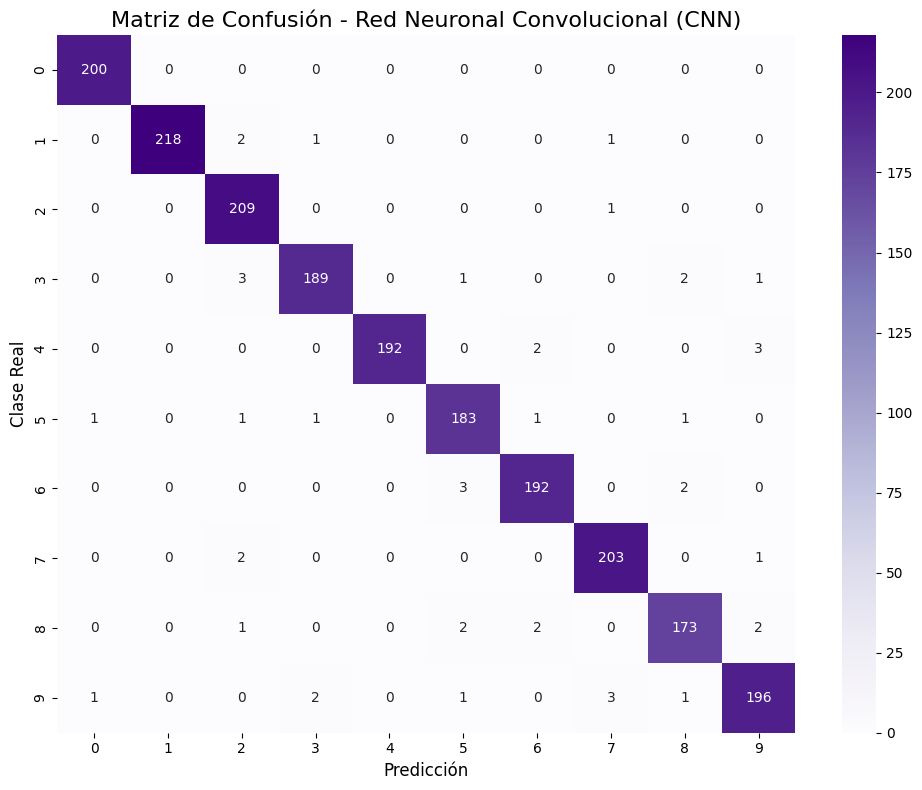

In [24]:
# 6. Graficar la matriz de confusión de la CNN
conf_matrix_cnn = confusion_matrix(y_test, y_pred_cnn)

plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix_cnn, annot=True, fmt='d', cmap='Purples',
            xticklabels=range(10), yticklabels=range(10))

plt.title('Matriz de Confusión - Red Neuronal Convolucional (CNN)', fontsize=16)
plt.xlabel('Predicción', fontsize=12)
plt.ylabel('Clase Real', fontsize=12)
plt.tight_layout()
plt.show()